In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors
import statsmodels.api as sm
import matplotlib.collections as mcoll

from analysis import *

In [2]:
med = df.query('scenario == "full_pipeline"')['r_opt'].median()
print(f'The median drift rate is {med:.2f}.')

The median drift rate is 2.16.


In [14]:
# supplement_mode: determines whether to plot the figure that goes in
# the main body, or the extended version in the supplement.
supplement_mode = True

if supplement_mode:
    scenario_map = {
        'full_pipeline': 'Exp. data',
        'full_pipeline_TQ14': 'Exp. data\n(TQ 14)',
        'full_pipeline_MP0.95': 'Exp. data\n(MP 0.95)',
        'no_cluster': 'Exp. data\n(no cluster)'
    }

    order = ['Exp. data', 'Exp. data\n(TQ 14)', 'Exp. data\n(MP 0.95)', 'Exp. data\n(no cluster)']
else:
    scenario_map = {
        'full_pipeline': 'Experimental\ndata',
        'r36_rp0.5_mimic': 'Sim. data\n(rp=0.5)',
        'r36_rp2_mimic': 'Sim. data\n(rp=2)',
        'r36_rp8_mimic': 'Sim. data\n(rp=8)',
        'r36_rp25_mimic': 'Sim. data\n(rp=25)',
    }
    
    order = ['Experimental\ndata', 'Sim. data\n(rp=0.5)', 'Sim. data\n(rp=2)', 'Sim. data\n(rp=8)', 'Sim. data\n(rp=25)']

df_plot = df.query('scenario.isin(@scenario_map.keys())').copy()
df_plot = df_plot.query('duplicate == 0').copy()
df_plot['scenario_label'] = df_plot['scenario'].map(scenario_map)

zero_counts = df_plot.groupby('scenario_label')['r_opt'].apply(lambda x: (x==0).mean()*100)

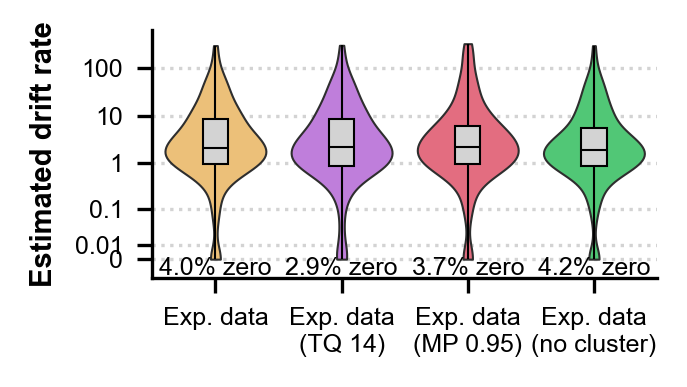

In [16]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

if supplement_mode:
    fig, ax = plt.subplots(figsize = (2.3, 1.3), dpi = 300)    
    filepath = os.path.join('images', 'fig4', 'violin_supplement.svg')
else:
    fig, ax = plt.subplots(figsize = (3.4, 1.8), dpi = 300)    
    filepath = os.path.join('images', 'fig4', 'violin.svg')

sns.violinplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    inner=None, cut=0, hue='scenario_label',
    density_norm='area', linewidth=0.5, palette=palette, ax=ax, legend=False
)

sns.boxplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    whis=np.inf, width=0.2, showcaps=False,
    boxprops={'facecolor':'lightgray', 'edgecolor':'black', 'linewidth':0.5},
    whiskerprops={'color':'black', 'linewidth':0.5},
    capprops={'color':'black', 'linewidth':0.5},
    medianprops={'color':'black', 'linewidth':0.5},
    ax=ax
)

# "True" r values in red dashed lines
if not supplement_mode:
    for i, r in enumerate([0.5, 2, 8, 25]):
        col = i + 1# + (len(order) - 4)
        y_val = symlog10(r, linthresh=1e-2)  
        
        poly = ax.collections[col]
        verts = poly.get_paths()[0].vertices
        mask = np.isclose(verts[:,1], y_val, atol=0.05)  # tolerance around y_val
        x_coords = verts[mask,0]
        
        xmin, xmax = x_coords.min(), x_coords.max()
        ax.hlines(
            y_val, xmin, xmax, colors='red', linestyles='dashed', linewidth=1
        )

for i, key in enumerate(order):
    pct = zero_counts.get(key, 0)
    ax.text(
        i, -0.2, f"{pct:.1f}% zero",
        ha='center', va='center', fontsize=6
    )

ax.set_xlabel('')

# Set y ticks.
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax.set_yticks(tick_symlog)
ax.set_yticklabels([str(r) for r in tick_r])
if supplement_mode:
    ax.set_ylim([-0.4, 4.5])
else:
ax.set_ylim([-0.4, 4.8])
ax.set_ylabel('Estimated drift rate', fontweight = 'bold')


ax.grid(True, linestyle=':', linewidth=0.8, color='lightgray', axis='y')
ax.set_axisbelow(True) 

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(filepath, pad_inches = 0)